# 00 全データ勾配による TT-Linear の 2-core スイープ学習

このNotebookは、物理DMRGの基礎から、Fashion-MNIST の未学習MLPに対する DMRG-like な 2-core 局所更新へつなぐ。行うのは次の学習である。

全学習データの平均勾配を用い、隣接TT pairと共有通常parameterからなる重複blockを左右に巡回して更新し、TT pairをrank制限SVDで再分割するDMRG-like学習。

局所固有値問題を解く物理DMRGそのものではない。minibatch SGDでもない。

## 計算量

6 core、`LOCAL_STEPS_PER_PAIR = L` のとき、1往復は左右で `2 * (6 - 1) * L = 10L` 回の全学習データ forward / backward である。往復の終わりに、学習データ全体と early-stopping validation の評価が加わる。

`MAX_SWEEPS` は最大往復数であり、通常の epoch 数と同じ感覚で置かない。`L = 1`、`MAX_SWEEPS = 5` なら、勾配計算だけで全学習データを 50 回なめる。

このセル以降の学習セルを Run All すると、その本設定の学習が始まる。小さいデータへの置き換えはしない。


## 1. この学習の位置

- 勾配は、全学習データの平均 cross-entropy である。minibatch は、その勾配を足し合わせるための分割である。batch ごとに parameter は更新しない。
- 各 pair では勾配を 1 歩進めるだけであり、局所問題を厳密には最小化しない。
- `fc1.bias`、`fc2`、`fc3` はすべての pair に共通して含まれる。TT core だけの更新実験ではない。したがって、指標の変化を TT 更新だけの効果とは解釈しない。
- SVD の rank 制限は、結合行列の Frobenius ノルムに関する最良低 rank 近似である。分類損失の最小化ではない。
- 損失が単調に減ること、early stopping、最大往復への到達は、数学的収束の証明ではない。

1往復は、中心が左端から右端へ進み、右端から左端へ戻ることである。6 core では次の 10 回である（`LOCAL_STEPS_PER_PAIR = 1`）。

- 右向き: `(0,1), (1,2), (2,3), (3,4), (4,5)`
- 左向き: `(4,5), (3,4), (2,3), (1,2), (0,1)`

折り返しの `(4,5)` は、右向きと左向きで別々に更新する。通常 parameter はこの 10 回のすべてで更新される。

A方式（minibatch を固定してスイープし、次の minibatch へモデルを渡す方式）はここでは実装しない。


## 2. 実験条件

新規の `MNISTMLP` を作り、未学習の `fc1`（784 → 512）だけを 6 core の `TTLinear` にする。`fc2`（512 → 256）と `fc3`（256 → 10）は通常の線形層のままである。活性化は `MNISTMLP` の ReLU のままである。学習済み checkpoint は使わない。

tensorization は次で固定する。

- `OUT_MODES = (4, 2, 2, 2, 4, 4)`。積は 512。
- `IN_MODES = (2, 2, 2, 2, 7, 7)`。積は 784。

core の軸順は `(r_left, out_mode, in_mode, r_right)` である。内部 bond の上限 `RANK_CAP = 12` を、既存の TT-SVD に渡す。形状だけから決まる上限は `(1, 8, 12, 12, 12, 12, 1)` である。これは数値的に得られた rank とは別の量なので、実行時の core shape を別に表示する。

`TT_PAIR_LEARNING_RATE` と `DENSE_PARAMETER_LEARNING_RATE` は別変数である。初期値はどちらも `1e-3` とする。この数は、`notebooks/30_tt_mps/10_fashion_mnist_mlp/14_rank12_update_scope_ablation.ipynb` の Adam の学習率と同じ数字である。こちらは momentum も適応的な更新もない素の勾配ステップであり、二つの学習率を同じにする妥当性は確認していない。両方とも未検証の初期 baseline である。

`BATCH_SIZE = 64` は、同じ Notebook 14 の mini-batch サイズを、勾配を小分けする単位として仮に置いたものである。SGD の batch サイズとして調整した値ではない。

`MAX_SWEEPS = 5`、`EARLY_STOPPING_PATIENCE = 5`、`EARLY_STOPPING_MIN_DELTA = 1e-5` は、性能上検証済みの設定ではない。2往復で早期終了するのを避け、5往復の傾向と相対更新量を観察し、その後に学習率や初期化スケールを判断するための予備設定である。学習率は変えていない。

データは既存の seed 0、50,000 / 5,000 / 5,000 分割を使う。先頭が学習、次が early-stopping validation、最後が rank-selection validation である。test と rank-selection validation は取得しても走査しない。


In [1]:
# 【このセルでやること】
# import とパス設定だけ。学習・データ読み込みはまだしない。

import os

# OpenMP が二重ロードされると Windows で落ちることがあるので、重複を許可する。
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import copy
import math
import sys
from pathlib import Path

import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader

# cwd から親へ遡り、src/nn_compression があるリポジトリ直下を見つける。
# notebook をどのカレントから開いても import できるようにするため。
for candidate in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    src_dir = candidate / "src"
    if (src_dir / "nn_compression").is_dir():
        if str(src_dir) not in sys.path:
            sys.path.insert(0, str(src_dir))
        break
else:
    # for が break せず終わった = どの親にも src/nn_compression が無い
    raise RuntimeError("src/nn_compression が見つかりません。")

# compression: TT 化・正準化・dense 復元
# datasets / models / training / utils: データ分割・MLP・評価・乱数と実験ディレクトリ
from nn_compression.compression import (
    assign_tt_linear_cores,
    factorize_named_tt_linear,
)
from nn_compression.tt_mps import (
    canonicalize_tt_matrix_cores,
    tt_matrix_ranks,
    tt_matrix_to_dense,
)
from nn_compression.datasets import (
    get_fashion_mnist_datasets,
    split_fashion_mnist_dataset,
)
from nn_compression.models import MNISTMLP
from nn_compression.training import evaluate
from nn_compression.utils import find_project_root, get_experiment_dirs, set_seed


In [2]:
# 【このセルでやること】
# 実験定数・乱数・保存先を決める。モデルやデータはまだ作らない。

SEED = 0

# fc1 の出力 512 を 6 個のモードに分解: 4*2*2*2*4*4 = 512
OUT_MODES = (4, 2, 2, 2, 4, 4)
# fc1 の入力 784 を 6 個のモードに分解: 2*2*2*2*7*7 = 784
# OUT_MODES[k], IN_MODES[k] が同じ site k の物理次元になる。
IN_MODES = (2, 2, 2, 2, 7, 7)

# TT-SVD と 2-site 再分割で許す内部 bond rank の上限
RANK_CAP = 12

# 全データ勾配を足すときの「何枚ずつ GPU に乗せるか」。
# ここでの 1 batch ごとに parameter は更新しない（SGD の mini-batch ではない）。
BATCH_SIZE = 64

# 有限性チェック用に固定で取る先頭サンプル数（学習には使わない）
DIAGNOSTIC_BATCH_SIZE = 64

# 各 pair (k,k+1) で勾配ステップを何回やるか。今は 1 回だけ。
LOCAL_STEPS_PER_PAIR = 1

# 左右 1 往復を最大何回繰り返すか。epoch 数ではない。
MAX_SWEEPS = 5

# η_T: 結合した 2-site テンソル T の学習率
TT_PAIR_LEARNING_RATE = 1e-3
# η_θ: bias / fc2 / fc3 など dense 側の学習率（T とは別）
DENSE_PARAMETER_LEARNING_RATE = 1e-3

# val_loss が min_delta 超で改善しない往復が patience 回続くと停止
EARLY_STOPPING_PATIENCE = 5
EARLY_STOPPING_MIN_DELTA = 1e-5

# TT 化する層の名前（MNISTMLP の第一線形層）
LAYER_NAME = "fc1"

# 60,000 枚を train / early-stop 用 val / rank 選択用に分割
SPLIT_LENGTHS = (50_000, 5_000, 5_000)

# モード積が本当に 512 / 784 になっているか確認
assert math.prod(OUT_MODES) == 512
assert math.prod(IN_MODES) == 784

set_seed(SEED)
project_root = find_project_root(Path.cwd())
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# この実験専用の data / models / results ディレクトリを用意
data_dir, models_dir, results_dir = get_experiment_dirs(
    project_root,
    "40_dmrg",
    "10_fashion_mnist_mlp",
    "00_full_batch_two_core_sweep_training",
)
print("device:", DEVICE)
print("models:", models_dir)
print("results:", results_dir)

# 後続セルの接続関数（加重損失・更新候補・方向付き因子・中心移動）の検証結果を貯める
todo_results = []


def report_todo(name, value, check):
    """接続関数の TODO 検証。失敗したときだけ例外を投げて学習セルを止める。"""
    if value is None:
        # まだ実装していない印。SKIP は「検証成功」ではない。
        print(f"SKIP | {name} | TODO未実装。これは検証成功ではない。")
        todo_results.append(("SKIP", name))
        return
    try:
        check()
    except Exception as error:
        print(f"検証失敗 | {name} | {type(error).__name__}: {error}")
        todo_results.append(("検証失敗", name))
        raise
    print(f"検証成功 | {name}")
    todo_results.append(("検証成功", name))


device: cuda
models: D:\dev\nn-compression-svd-dmrg\models\40_dmrg\10_fashion_mnist_mlp\00_full_batch_two_core_sweep_training
results: D:\dev\nn-compression-svd-dmrg\results\40_dmrg\10_fashion_mnist_mlp\00_full_batch_two_core_sweep_training


## 3. データ

Fashion-MNIST は `ToTensor` だけを使う。ランダムな切り抜きや反転はない。勾配用 loader は `shuffle=False`、`drop_last=False` にする。shuffle する学習 loader の `next(iter(...))` では batch を取らない。

test と rank-selection validation は、分割 API が返すので変数には残す。評価も設定選択もせず、画像は読まない。


In [3]:
# 【このセルでやること】
# Fashion-MNIST を読み、分割し、DataLoader を用意する。

# torchvision が置く raw ファイルがあるか確認（無いなら代替データでは学習しない）
fashion_root = data_dir / "FashionMNIST" / "raw"
required = [
    "train-images-idx3-ubyte",
    "train-labels-idx1-ubyte",
    "t10k-images-idx3-ubyte",
    "t10k-labels-idx1-ubyte",
]
missing = [name for name in required if not (fashion_root / name).is_file()]
if missing:
    raise FileNotFoundError(
        "Fashion-MNIST がありません。代替データでは学習しない: " + ", ".join(missing)
    )

# download=False: ネットから取らず、手元のファイルだけ使う
full_train_dataset, test_dataset = get_fashion_mnist_datasets(
    data_dir,
    download=False,
)

# 60,000 → 50k / 5k / 5k。seed 固定なので分割は再現できる。
train_dataset, early_stopping_dataset, rank_validation_dataset = split_fashion_mnist_dataset(
    full_train_dataset,
    SPLIT_LENGTHS,
    seed=SEED,
)
assert len(train_dataset) == 50_000
assert len(early_stopping_dataset) == 5_000
assert len(rank_validation_dataset) == 5_000

# ∇L を全 train で足し合わせる用。
# shuffle=False: 毎回同じ順でなめて、全データ平均 L = Σ_b (n_b/N) L_b を安定に作る。
# drop_last=False: 最後の端数 batch も捨てない（N に含めるため）。
gradient_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
)

# 往復ごとの train 評価用（parameter は更新しない）
train_eval_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
)

# early stopping 判定用。rank 選択用・test はこの Notebook では走査しない。
validation_loader = DataLoader(
    early_stopping_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
)

# 候補の NaN/Inf チェック用の固定 batch。
# 「先頭 64 枚が有限 ⇒ 全データが有限」の証明ではない。
diagnostic_images = torch.stack(
    [train_dataset[index][0] for index in range(DIAGNOSTIC_BATCH_SIZE)]
)
diagnostic_labels = torch.tensor(
    [train_dataset[index][1] for index in range(DIAGNOSTIC_BATCH_SIZE)]
)


def split_identity(subset):
    """分割の再現確認用。Subset.indices の先頭・末尾だけ返す。"""
    indices = list(subset.indices)
    return {
        "n": len(indices),
        "head": indices[:5],
        "tail": indices[-5:],
    }


print("transform: ToTensor only")
print("train", split_identity(train_dataset))
print("early_stopping_validation", split_identity(early_stopping_dataset))
print(
    "rank_selection_validation exists but is not scanned:",
    len(rank_validation_dataset),
)
print("test exists but is not scanned:", len(test_dataset))
print("diagnostic batch:", tuple(diagnostic_images.shape), tuple(diagnostic_labels.shape))


transform: ToTensor only
train {'n': 50000, 'head': [36044, 10678, 57327, 55074, 21567], 'tail': [49628, 13838, 23049, 33946, 34814]}
early_stopping_validation {'n': 5000, 'head': [59375, 23261, 23868, 32266, 29784], 'tail': [1274, 42584, 38514, 54642, 11687]}
rank_selection_validation exists but is not scanned: 5000
test exists but is not scanned: 10000
diagnostic batch: (64, 1, 28, 28) (64,)


## 4. 新規モデル

`fc1` を TT-SVD し、中心を site 0 へ正準化する。この状態が sweep 0、つまり初期モデルである。`fc1.bias` は新規 dense モデルの bias を引き継ぐ。`fc2` と `fc3` も同じ新規モデルの parameter である。

形状上の rank 上限と、実際の core shape から読んだ rank は別に表示する。


In [4]:
# 【このセルでやること】
# 未学習 MLP の fc1 を TT 化し、site 0 中心の正準形にして sweep 0（初期モデル）にする。


def shape_rank_upper_bounds(out_modes, in_modes, max_rank):
    """形状だけから決まる bond 上限 (1, r1, ..., 1)。

    TT の各内部 bond は、左に積もった次元・右に残った次元・max_rank の
    3 つのうち最小までしか取れない、という上界。
    実行時の actual ranks（TT-SVD 後の実 rank）とは別物。
    """
    left = 1
    # 全サイトの (m_k * n_k) の積 = 行列の要素数 512*784
    remaining = math.prod(out_mode * in_mode for out_mode, in_mode in zip(out_modes, in_modes))
    ranks = [1]  # 左端の仮想 bond は常に 1
    for index, (out_mode, in_mode) in enumerate(zip(out_modes, in_modes)):
        left *= out_mode * in_mode          # このサイトまで左側に積もった次元
        remaining //= out_mode * in_mode    # 右側にまだ残っている次元
        if index == len(out_modes) - 1:
            ranks.append(1)  # 右端の仮想 bond も常に 1
        else:
            # bond r_{k+1} ≤ min(左の自由度, 右の自由度, RANK_CAP)
            ranks.append(min(left, remaining, max_rank))
    return tuple(ranks)


# 未学習の dense MLP（まだ 1 epoch も回していない）
dense_model = MNISTMLP()
# TT-SVD 前後で ||W|| がどれだけ変わったか見るための基準ノルム
dense_fc1_weight_norm = float(torch.linalg.vector_norm(dense_model.fc1.weight.detach()))

# fc1: Linear → TTLinear（6 core）。中身は deepcopy したコピー側だけ置換する。
model = factorize_named_tt_linear(
    dense_model,
    LAYER_NAME,
    OUT_MODES,
    IN_MODES,
    max_rank=RANK_CAP,
)

# 直交中心を左端 site 0 へ移す（混合正準形）。
# gauge 変換なので、丸め誤差を除き dense に戻した W の値は変わらない。
# list(...) にしているのは ParameterList を素の list[Tensor] として渡すため。
canonical_cores = canonicalize_tt_matrix_cores(
    list(model.fc1.cores),
    OUT_MODES,
    IN_MODES,
    center=0,
)
# requires_grad=False: core は「結合して T にしたときだけ」勾配を取る設計。
# 単独の core.grad はスイープ中は使わない。
assign_tt_linear_cores(model.fc1, canonical_cores, requires_grad=False)

# スイープ中に動かす通常 parameter は bias / fc2 / fc3 だけ。
# 名前が "fc1.cores.*" でないものを requires_grad=True にする。
for name, parameter in model.named_parameters():
    if not name.startswith(f"{LAYER_NAME}.cores."):
        parameter.requires_grad_(True)
model.to(DEVICE)

# 形状上界・実 rank・各 core の形を記録
shape_bounds = shape_rank_upper_bounds(OUT_MODES, IN_MODES, RANK_CAP)
actual_ranks = tt_matrix_ranks(list(model.fc1.cores))
core_shapes = [tuple(core.shape) for core in model.fc1.cores]

# TT cores → dense 行列 W に戻してノルム比較（近似誤差の目安）
weight = tt_matrix_to_dense(list(model.fc1.cores), OUT_MODES, IN_MODES)
parameter_vector = torch.cat([parameter.detach().flatten() for parameter in model.parameters()])

# 診断 batch で forward が有限か確認（学習ステップではない）
logits = model(diagnostic_images.to(DEVICE))
diagnostic_loss = F.cross_entropy(logits, diagnostic_labels.to(DEVICE))
parameters_finite = all(torch.isfinite(parameter).all() for parameter in model.parameters())

print("fc1: TTLinear", model.fc1.in_features, "->", model.fc1.out_features)
print("fc2:", tuple(model.fc2.weight.shape), "fc3:", tuple(model.fc3.weight.shape))
print("core shapes:", core_shapes)
print("shape rank upper bounds:", shape_bounds)
print("actual ranks:", actual_ranks)
print("dtype:", model.fc1.cores[0].dtype, "device:", model.fc1.cores[0].device)

tt_fc1_weight_norm = float(torch.linalg.vector_norm(weight))
if dense_fc1_weight_norm == 0.0:
    raise ValueError("TT-SVD前の fc1 weight norm が 0 なので比を定義できません。")
# 1 に近いほど、TT-SVD + 正準化で ||W|| が保たれている
weight_norm_ratio = tt_fc1_weight_norm / dense_fc1_weight_norm
print("dense fc1 weight norm before TT-SVD:", dense_fc1_weight_norm)
print("tt fc1 weight norm after canonicalize:", tt_fc1_weight_norm)
print("tt_norm / dense_norm:", weight_norm_ratio)
print("all parameter norm:", float(torch.linalg.vector_norm(parameter_vector)))
print(
    "diagnostic finite:",
    bool(torch.isfinite(logits).all() and torch.isfinite(diagnostic_loss)),
    "parameters finite:",
    parameters_finite,
)

# 損失は平均 cross-entropy。これが往復ごとの評価にも使われる。
criterion = torch.nn.CrossEntropyLoss()
train_loss, train_acc = evaluate(model, train_eval_loader, criterion, DEVICE)
val_loss, val_acc = evaluate(model, validation_loader, criterion, DEVICE)
print("sweep 0 train loss/acc:", train_loss, train_acc)
print("sweep 0 validation loss/acc:", val_loss, val_acc)

# 学習前の state を控える（必要なら初期に戻せる）
initial_state = copy.deepcopy(model.state_dict())


fc1: TTLinear 784 -> 512
fc2: (256, 512) fc3: (10, 256)
core shapes: [(1, 4, 2, 8), (8, 2, 2, 12), (12, 2, 2, 12), (12, 2, 2, 12), (12, 4, 7, 12), (12, 4, 7, 1)]
shape rank upper bounds: (1, 8, 12, 12, 12, 12, 1)
actual ranks: (1, 8, 12, 12, 12, 12, 1)
dtype: torch.float32 device: cuda:0
dense fc1 weight norm before TT-SVD: 13.063002586364746
tt fc1 weight norm after canonicalize: 1.8824597597122192
tt_norm / dense_norm: 0.14410620737969876
all parameter norm: 12.188812255859375
diagnostic finite: True parameters finite: True
sweep 0 train loss/acc: 2.303470165863037 0.09358
sweep 0 validation loss/acc: 2.3039831802368163 0.0946


## 5. 全データ勾配の重み

batch の平均 cross-entropy を $L_b$、その batch の sample 数を $n_b$、全学習 sample 数を $N$ とする。全データの平均損失は

$$
L = \sum_b \frac{n_b}{N} L_b
$$

である。足す勾配は、この重み付き損失の勾配である。$L_b$ がすでに平均なので、さらに $N$ では割らない。最終 batch の $n_b$ が違っても同じ式である。

集計が終わるまで、$T$ も通常 parameter も値を変えない。


In [ ]:
# 【このセルでやること】
# 1 batch の平均損失を、全データ平均 L の 1 項に直す関数を定義・検証する。


def weighted_batch_loss(loss_b, n_b, N):
    # loss_b : その batch の平均 CE（すでに 1/n_b で平均されている）
    # n_b    : その batch の sample 数
    # N      : 全学習 sample 数
    #
    # 全データ平均は
    #   L = (1/N) Σ_i ℓ_i = Σ_b (n_b / N) * (batch 平均 L_b)
    # なので、この関数は「Σ に足す 1 項」だけを返す。
    # ここでさらに /N してはいけない（二重割りになる）。
    return loss_b * (n_b / N)


# 検算: L_b=2, n_b=4, N=10 → (4/10)*2 = 0.8
report_todo(
    "加重batch損失",
    weighted_batch_loss(torch.tensor(2.0), 4, 10),
    lambda: torch.testing.assert_close(
        weighted_batch_loss(torch.tensor(2.0), 4, 10),
        torch.tensor(0.8),
    ),
)


検証成功 | 加重batch損失


## 6. 二つの学習率

同じ更新前の損失から、結合テンソル $T$ と通常 parameter $\theta$ の勾配を取る。更新候補は

$$
T_{\mathrm{candidate}} = T - \eta_{T} g_T,
\qquad
\theta_{\mathrm{candidate}} = \theta - \eta_{\theta} g_{\theta}
$$

である。$\eta_T$ と $\eta_\theta$ は別である。momentum、weight decay、Adam は使わない。

対象外は、今の pair 以外の `fc1` core である。対象 pair の元 core にも勾配は流さない。


In [6]:
# 【このセルでやること】
# 現在値・勾配・専用学習率から更新候補を作る関数を定義・検証する。


def parameter_candidate(value, gradient, learning_rate):
    # 素の勾配ステップ（Adam / momentum / weight decay なし）
    #   candidate = value - η * gradient
    # T 用なら η=η_T、dense 用なら η=η_θ を渡す。
    return value - learning_rate * gradient


# 検算: 1.0 - 0.2*0.5 = 0.9
report_todo(
    "学習率を分けた更新候補",
    parameter_candidate(torch.tensor(1.0), torch.tensor(0.5), 0.2),
    lambda: torch.testing.assert_close(
        parameter_candidate(torch.tensor(1.0), torch.tensor(0.5), 0.2),
        torch.tensor(0.9),
    ),
)


検証成功 | 学習率を分けた更新候補


## 7. 方向付き SVD

結合テンソルの軸は $(r_{k-1}, m_k, n_k, m_{k+1}, n_{k+1}, r_{k+1})$ である。行列 $M$ は、左を $(r_{k-1}, m_k, n_k)$、右を $(m_{k+1}, n_{k+1}, r_{k+1})$ として作る。保持成分は

$$
M_r = U_r \Sigma_r V_r^{\mathsf T}
$$

である。

- 右向き: 左 core は $\mathrm{reshape}(U_r)$、右 core は $\mathrm{reshape}(\Sigma_r V_r^{\mathsf T})$。中心は pair の右 site へ移る。
- 左向き: 左 core は $\mathrm{reshape}(U_r \Sigma_r)$、右 core は $\mathrm{reshape}(V_r^{\mathsf T})$。中心は pair の左 site へ移る。

特異値も core も、ノルム 1 には戻さない。SVD は逆伝播に入れない。


In [7]:
# 【このセルでやること】
# 還元 SVD の U, Σ, V^T から、スイープ向きに応じた左右因子を返す。


def directional_factors(u_factor, singular_values, vh, direction):
    # 入力は torch.linalg.svd(M, full_matrices=False) の結果:
    #   M ≈ U @ diag(Σ) @ Vh ,  形は U:(m,r), Σ:(r,), Vh:(r,n)
    #
    # 右向き（中心を右へ移す）:
    #   左因子 = U          ← 新しい左 core（直交側）
    #   右因子 = Σ Vh       ← 特異値を右に吸収（broadcast: Σ[:,None] * Vh）
    # 左向き（中心を左へ移す）:
    #   左因子 = U Σ        ← 特異値を左に吸収（broadcast: U * Σ[None,:]）
    #   右因子 = Vh         ← 新しい右 core（直交側）
    if direction == "right":
        left = u_factor
        # singular_values.unsqueeze(1): (r,) → (r,1) にして行方向へ掛ける
        right = singular_values.unsqueeze(1) * vh
    elif direction == "left":
        # unsqueeze(0): (r,) → (1,r) にして列方向へ掛ける
        left = u_factor * singular_values.unsqueeze(0)
        right = vh
    else:
        raise ValueError(
            f'direction は "right" または "left" である必要があります: {direction!r}'
        )
    return left, right


def _check_directional_factors():
    generator = torch.Generator().manual_seed(0)
    matrix = torch.randn(6, 5, generator=generator)
    u_factor, singular_values, vh = torch.linalg.svd(matrix, full_matrices=False)
    # 元の行列の再構成（向きに依存しない正解）
    reconstruction = (u_factor * singular_values.unsqueeze(0)) @ vh
    for direction in ("right", "left"):
        left, right = directional_factors(u_factor, singular_values, vh, direction)
        # どちらの向きでも left @ right は同じ M を再現する
        torch.testing.assert_close(left @ right, reconstruction)
        if direction == "right":
            # 右向き: 左因子が列直交 → left^T left = I
            identity = torch.eye(left.shape[1])
            torch.testing.assert_close(left.T @ left, identity, atol=1e-6, rtol=1e-6)
        else:
            # 左向き: 右因子が行直交 → right right^T = I
            identity = torch.eye(right.shape[0])
            torch.testing.assert_close(right @ right.T, identity, atol=1e-6, rtol=1e-6)


# probe が None なら「未実装」扱い（report_todo が SKIP する）
probe = directional_factors(
    torch.eye(2),
    torch.ones(2),
    torch.eye(2),
    "right",
)
report_todo("方向付き因子", None if probe is None else probe, _check_directional_factors)


検証成功 | 方向付き因子


## 8. 中心の引き継ぎ

学習開始時に site 0 を中心へ正準化する。そのあと、毎 pair で列全体は正準化し直さない。成功した分割の向きだけで中心を進める。

右向きに成功した pair $(k, k+1)$ の中心は site $k+1$ である。左向きに成功した同じ pair の中心は site $k$ である。同じ pair の 2 step 目では、中心は進入側ではなく、pair の中の出口側にあってよい。pair の外には出さない。

6 core で 1 往復が正常に終わると、中心は site 0 に戻る。


In [8]:
# 【このセルでやること】
# 分割成功後に直交中心がどの site へ移るかを返す関数を定義・検証する。


def center_after_successful_split(pair_index, direction):
    # pair_index = k は「site k と site k+1 を結合していた」という意味。
    #
    # 右向き成功: 特異値を右へ渡したので、直交中心は右 site = k+1
    # 左向き成功: 特異値を左へ渡したので、直交中心は左 site = k
    if direction == "right":
        return pair_index + 1
    if direction == "left":
        return pair_index
    raise ValueError(
        f'direction は "right" または "left" である必要があります: {direction!r}'
    )


def _check_center():
    # pair (4,5) を右へ → 中心は site 5
    if center_after_successful_split(4, "right") != 5:
        raise AssertionError("右向きに成功した pair の中心は、その右 site です。")
    # pair (4,5) を左へ → 中心は site 4
    if center_after_successful_split(4, "left") != 4:
        raise AssertionError("左向きに成功した pair の中心は、その左 site です。")


report_todo(
    "分割後の中心",
    center_after_successful_split(4, "right"),
    _check_center,
)


検証成功 | 分割後の中心


## 9. 本設定の学習

ここから先は、上で確認した接続を、テスト済みの共有実装で本設定の学習として実行する。

候補の有限性は、先頭 64 件の固定診断 batch で見る。それは全学習データが有限であることは意味しない。損失が下がることは、候補を受け入れる条件ではない。

往復が途中で失敗した場合、最後に成功した局所更新までのモデルを残し、その往復は完了数に入れず、途中状態は best にしない。


In [9]:
# 【このセルでやること】
# 本学習: 隣接 2 core の結合 → 全データ勾配 → 1 ステップ → 方向付き SVD、を左右往復。

from nn_compression.training import (
    load_tt_linear_sweep_checkpoint,      # 保存セルで使う
    save_tt_linear_full_batch_sweep_run,  # 保存セルで使う
    train_tt_linear_full_batch_sweeps,    # ここで本学習を回す
)

# 中でやっている局所更新（1 pair・1 direction）の流れ:
#   1) cores[k], cores[k+1] を結合して T を作る
#   2) 動かさない core は凍結し、T と dense θ だけ勾配を取る
#   3) 全 train で L = Σ_b (n_b/N) L_b をなめて g_T, g_θ を集計
#   4) T ← T - η_T g_T ,  θ ← θ - η_θ g_θ
#   5) T を方向付き SVD で 2 core に戻し、中心を移動
# 1 往復 = 右向き (0,1)…(4,5) + 左向き (4,5)…(0,1)
result = train_tt_linear_full_batch_sweeps(
    model,
    gradient_loader,       # 全データ勾配を足す loader
    train_eval_loader,     # 往復後の train 評価
    validation_loader,     # early stopping 用 val 評価
    layer_name=LAYER_NAME,
    rank_cap=RANK_CAP,     # 再分割時の保持 rank 上限
    tt_pair_learning_rate=TT_PAIR_LEARNING_RATE,           # η_T
    dense_parameter_learning_rate=DENSE_PARAMETER_LEARNING_RATE,  # η_θ
    max_sweeps=MAX_SWEEPS,
    local_steps_per_pair=LOCAL_STEPS_PER_PAIR,
    early_stopping_patience=EARLY_STOPPING_PATIENCE,
    early_stopping_min_delta=EARLY_STOPPING_MIN_DELTA,
    diagnostic_images=diagnostic_images,   # 候補の有限性チェック用
    diagnostic_labels=diagnostic_labels,
    device=DEVICE,
    center=0,              # 初期の直交中心（正準化で site 0 にした）
    criterion=criterion,
)

# stop_reason 例: "early_stopping" / "max_sweeps" / 途中失敗など
print("stop:", result.stop_reason)
print(result.stop_detail)
print("completed sweeps:", result.completed_sweeps)
print("successful local updates:", result.successful_local_updates)
# 往復の途中で止まっても、それまでに成功した局所更新数
print("incomplete sweep successes:", result.incomplete_sweep_successes)
print("center:", result.center)
print("last success:", result.last_success_pair, result.last_success_direction)
print("best sweep:", result.best_sweep, "best validation loss:", result.best_validation_loss)
print("final ranks:", tt_matrix_ranks(list(model.fc1.cores)))

# --- 相対更新量（診断専用）---
# η ||g|| / ||parameter||
# 「今のステップ幅がパラメータ規模の何割か」を見るだけ。
# 候補の受理条件にも、early stopping にも使わない。
ok_logs = [row for row in result.local_updates if row["status"] == "ok"]
if ok_logs and "tt_relative_update" in ok_logs[0] and "dense_relative_update" in ok_logs[0]:
    tt_steps = [row["tt_relative_update"] for row in ok_logs]
    dense_steps = [row["dense_relative_update"] for row in ok_logs]
    print(
        "relative update tt min/max:",
        min(tt_steps),
        max(tt_steps),
        "dense min/max:",
        min(dense_steps),
        max(dense_steps),
    )
    last = ok_logs[-1]
    print(
        "last relative update:",
        "pair",
        last["pair_index"],
        last["direction"],
        "tt",
        last["tt_relative_update"],
        "dense",
        last["dense_relative_update"],
    )
    print("相対更新量は診断値であり、候補の受理条件でも停止条件でもない。")
elif ok_logs:
    # 古い実行結果や古い src だとキーが無いことがある
    print(
        "local_updates に tt_relative_update / dense_relative_update がありません。"
        "src を更新したあと、import し直してから再学習すると記録されます。"
    )
    print("keys:", sorted(ok_logs[0].keys()))


stop: max_sweeps
最大往復数 5 まで実行した。これは数学的収束の証明ではない。
completed sweeps: 5
successful local updates: 50
incomplete sweep successes: 0
center: 0
last success: 0 left
best sweep: 5 best validation loss: 2.3038700309753417
final ranks: (1, 8, 12, 12, 12, 12, 1)
relative update tt min/max: 4.1014267317870434e-06 2.7163311504172372e-05 dense min/max: 4.5778963613858604e-06 4.579054214478177e-06
last relative update: pair 0 left tt 4.108059591652292e-06 dense 4.579054214478177e-06
相対更新量は診断値であり、候補の受理条件でも停止条件でもない。


## 10. 履歴の読み方

sweep 0 は初期モデルである。各行の loss は、その往復が終わったあとの通常 forward による全データ評価である。最後の pair を更新する前の集計損失ではない。

validation loss が `EARLY_STOPPING_MIN_DELTA` を超えて改善しない往復が `EARLY_STOPPING_PATIENCE` 回続くと停止する。best は、その閾値より小さい改善でも、過去最小なら更新される。どちらも収束の証明ではない。

曲線が動いても、TT pair だけの効果とは読まない。通常 parameter が同じ往復の中で繰り返し更新されている。

各局所更新の `tt_relative_update` と `dense_relative_update` は、学習率を変える前に見る診断値である。候補を受け入れる条件にも、停止条件にも使わない。


sweep=0 train_loss=2.303470 train_acc=0.0936 val_loss=2.303983 val_acc=0.0946 stall=0 best=True
sweep=1 train_loss=2.303448 train_acc=0.0937 val_loss=2.303961 val_acc=0.0946 stall=0 best=True
sweep=2 train_loss=2.303425 train_acc=0.0938 val_loss=2.303938 val_acc=0.0948 stall=0 best=True
sweep=3 train_loss=2.303403 train_acc=0.0940 val_loss=2.303915 val_acc=0.0948 stall=0 best=True
sweep=4 train_loss=2.303381 train_acc=0.0942 val_loss=2.303893 val_acc=0.0948 stall=0 best=True
sweep=5 train_loss=2.303358 train_acc=0.0943 val_loss=2.303870 val_acc=0.0952 stall=0 best=True


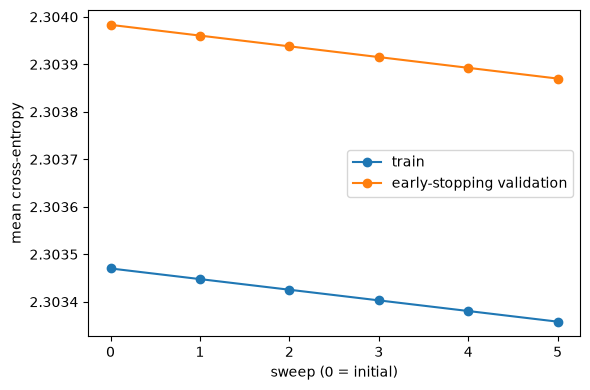

In [10]:
# 【このセルでやること】
# 往復ごとの履歴を表で出し、学習曲線を描いて保存する。

import matplotlib.pyplot as plt

# history の 1 行 = 1 往復終了後の全データ評価
# stall_count: val が min_delta 超で改善しなかった連続回数
# is_best: その時点までの最良 val なら True（微小改善でも過去最小なら更新）
for row in result.history:
    print(
        f"sweep={row['sweep']} train_loss={row['train_loss']:.6f} "
        f"train_acc={row['train_acc']:.4f} val_loss={row['validation_loss']:.6f} "
        f"val_acc={row['validation_acc']:.4f} stall={row['stall_count']} "
        f"best={row['is_best']}"
    )

figure, axis = plt.subplots(figsize=(6, 4))
# 横軸は sweep 番号（0 = 学習前の初期モデル）
axis.plot(
    [row["sweep"] for row in result.history],
    [row["train_loss"] for row in result.history],
    marker="o",
    label="train",
)
axis.plot(
    [row["sweep"] for row in result.history],
    [row["validation_loss"] for row in result.history],
    marker="o",
    label="early-stopping validation",
)
axis.set_xlabel("sweep (0 = initial)")
axis.set_ylabel("mean cross-entropy")
axis.legend()
figure.tight_layout()
figure.savefig(results_dir / "learning_curve.png", dpi=120)
plt.show()


## 11. 保存と再読み込み

先に最終モデルを保存する。そのあと、best を別のモデルへ読み、early-stopping validation の loss と accuracy が履歴の best 行と許容差内で一致するかを見る。

許容差は float32 の全データ集計に対して `atol = rtol = 1e-5` とする。同じ重み・同じ評価順なら、この桁よりずっと小さい差になる想定である。完全な学習再開用の optimizer state は保存しない。


In [11]:
# 【このセルでやること】
# 設定とモデルを保存し、best を別インスタンスで読み直して再評価する。

final_ranks = tt_matrix_ranks(list(model.fc1.cores))

# 再現用メタデータ。学習そのものには使わない。
config = {
    "model": "MNISTMLP fc1 TTLinear, fc2 Linear, fc3 Linear, ReLU",
    "out_modes": list(OUT_MODES),
    "in_modes": list(IN_MODES),
    "shape_rank_upper_bounds": list(shape_bounds),  # 形状から決まる上界
    "initial_ranks": list(actual_ranks),            # TT-SVD 直後の実 rank
    "rank_cap": RANK_CAP,
    "final_ranks": list(final_ranks),               # 学習後の実 rank
    "initialization": "new MNISTMLP, TT-SVD of untrained fc1, canonicalize center 0",
    "seed": SEED,
    "dtype": str(model.fc1.cores[0].dtype),
    "tt_pair_learning_rate": TT_PAIR_LEARNING_RATE,
    "dense_parameter_learning_rate": DENSE_PARAMETER_LEARNING_RATE,
    "learning_rates_are_provisional_baseline": True,  # 未チューニングの初期値
    "batch_size": BATCH_SIZE,
    "local_steps_per_pair": LOCAL_STEPS_PER_PAIR,
    "max_sweeps": MAX_SWEEPS,
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,
    "early_stopping_min_delta": EARLY_STOPPING_MIN_DELTA,
    "split": "Fashion-MNIST 50000/5000/5000 seed 0; train / early-stopping / rank-selection",
    # 分割の先頭 index を残すと、後から同じ split か照合できる
    "train_split_head": split_identity(train_dataset)["head"],
    "early_stopping_split_head": split_identity(early_stopping_dataset)["head"],
    "test_and_rank_selection_were_not_scanned": True,
    "layer_name": LAYER_NAME,
    "best_sweep": result.best_sweep,
    "best_validation_loss": result.best_validation_loss,
    "completed_sweeps": result.completed_sweeps,
    "successful_local_updates": result.successful_local_updates,
    "last_success_pair": result.last_success_pair,
    "last_success_direction": result.last_success_direction,
    "center": result.center,
    "incomplete_sweep_successes": result.incomplete_sweep_successes,
    "stop_reason": result.stop_reason,
    "stop_detail": result.stop_detail,
    "stop_sweep": result.stop_sweep,
    "stop_pair": result.stop_pair,
    "stop_direction": result.stop_direction,
    "stop_local_step": result.stop_local_step,
}

# final_model.pt = 最後に成功した局所更新までの state
# best_model.pt  = early-stopping 中の最良 validation の state
save_tt_linear_full_batch_sweep_run(models_dir, model, result, config)

# --- best の再ロード検証 ---
# 1) 同じ構造の空モデルを TT 化して骨格を作る
# 2) checkpoint を読む（中で CPU に載る）
# 3) そのあと DEVICE へ移す（先に .to(DEVICE) すると CPU tensor を CUDA へ
#    直接 load しようとして失敗することがある）
reloaded = factorize_named_tt_linear(
    MNISTMLP(),
    LAYER_NAME,
    OUT_MODES,
    IN_MODES,
    max_rank=RANK_CAP,
)
load_tt_linear_sweep_checkpoint(models_dir / "best_model.pt", reloaded)
reloaded = reloaded.to(DEVICE)

reloaded_loss, reloaded_acc = evaluate(reloaded, validation_loader, criterion, DEVICE)
# history から「best と記録した行」を拾い、再評価と一致するか確認
best_row = next(row for row in result.history if row["sweep"] == result.best_sweep)
print("reloaded validation:", reloaded_loss, reloaded_acc)
print("recorded best:", best_row["validation_loss"], best_row["validation_acc"])
torch.testing.assert_close(
    torch.tensor([reloaded_loss, reloaded_acc]),
    torch.tensor([best_row["validation_loss"], best_row["validation_acc"]]),
    atol=1e-5,
    rtol=1e-5,
)
print("best reload: 検証成功")
print("接続関数の確認:", todo_results)
print(
    "このモデルの最終 state は final_model.pt、最良 validation は best_model.pt である。"
    "停止理由は数学的収束ではない。"
)


reloaded validation: 2.3038700309753417 0.0952
recorded best: 2.3038700309753417 0.0952
best reload: 検証成功
接続関数の確認: [('検証成功', '加重batch損失'), ('検証成功', '学習率を分けた更新候補'), ('検証成功', '方向付き因子'), ('検証成功', '分割後の中心')]
このモデルの最終 state は final_model.pt、最良 validation は best_model.pt である。停止理由は数学的収束ではない。
